In [ ]:
# Install the libraries needed for our project
!pip -q install pandas numpy matplotlib seaborn scikit-learn openpyxl

print("Project setup completed successfully!")

Project setup completed successfully!


In [ ]:
import pandas as pd
import os

# Check uploaded files
os.listdir('/content')

['.config', 'online_retail_II.csv', 'sample_data']

In [ ]:
file_path = '/content/online_retail_II.xlsx'

df = pd.read_csv("online_retail_II.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [ ]:
# Check column names
print(df.columns.tolist())

# Check missing values
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64
Duplicate rows: 34335


In [ ]:
# Remove duplicate rows
df = df.drop_duplicates()

# Remove rows without Customer ID
df = df.dropna(subset=['Customer ID'])

# Remove invalid quantities and prices
df = df[(df['Quantity'] > 0) & (df['Price'] > 0)]

# Create total sales column
df['TotalSales'] = df['Quantity'] * df['Price']

print("Cleaned dataset shape:", df.shape)
print(df.head())

Cleaned dataset shape: (779425, 9)
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

           InvoiceDate  Price  Customer ID         Country  TotalSales  
0  2009-12-01 07:45:00   6.95      13085.0  United Kingdom        83.4  
1  2009-12-01 07:45:00   6.75      13085.0  United Kingdom        81.0  
2  2009-12-01 07:45:00   6.75      13085.0  United Kingdom        81.0  
3  2009-12-01 07:45:00   2.10      13085.0  United Kingdom       100.8  
4  2009-12-01 07:45:00   1.25      13085.0  United Kingdom        30.0  


In [ ]:
df.to_csv('/content/cleaned_retail_data.csv', index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


Monthly Sales:
Month
2009-12     683504.010
2010-01     555802.672
2010-02     504558.956
2010-03     696978.471
2010-04     591982.002
2010-05     597833.380
2010-06     636371.130
2010-07     589736.170
2010-08     602224.600
2010-09     829013.951
2010-10    1033112.010
2010-11    1166460.022
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517208.440
Name: TotalSales, dtype: float64


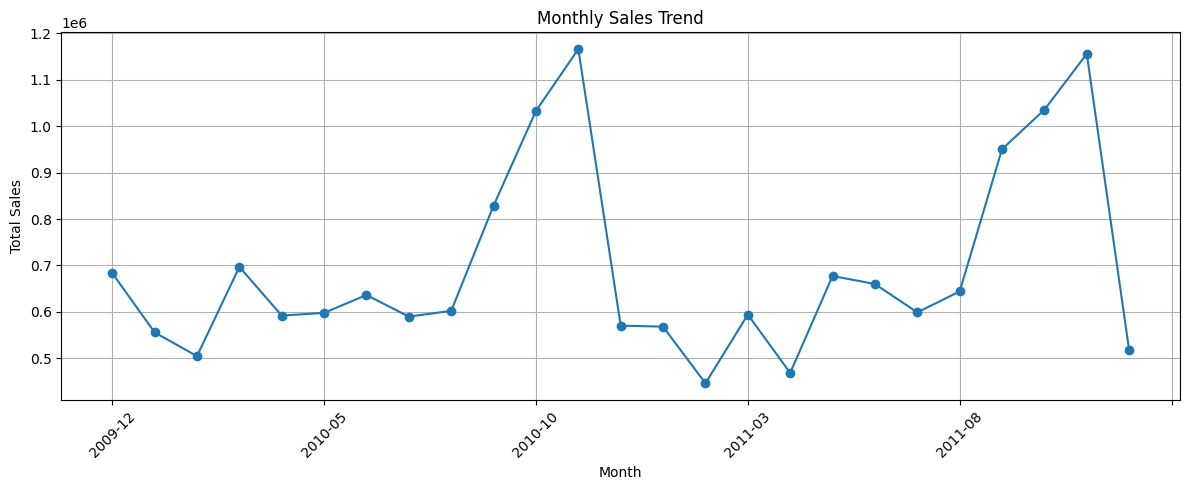

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Convert invoice date to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Extract month
df['Month'] = df['InvoiceDate'].dt.to_period('M').astype(str)

# Calculate monthly sales
monthly_sales = df.groupby('Month')['TotalSales'].sum()

# Display results
print("Monthly Sales:")
print(monthly_sales)

# Plot graph
plt.figure(figsize=(12, 5))
monthly_sales.plot(kind='line', marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

StockCode
22423     277656.25
85123A    247203.36
23843     168469.60
85099B    167920.64
M         151777.67
POST      124648.04
84879     124351.86
47566     103283.38
23166      81416.73
22086      76598.18
Name: TotalSales, dtype: float64


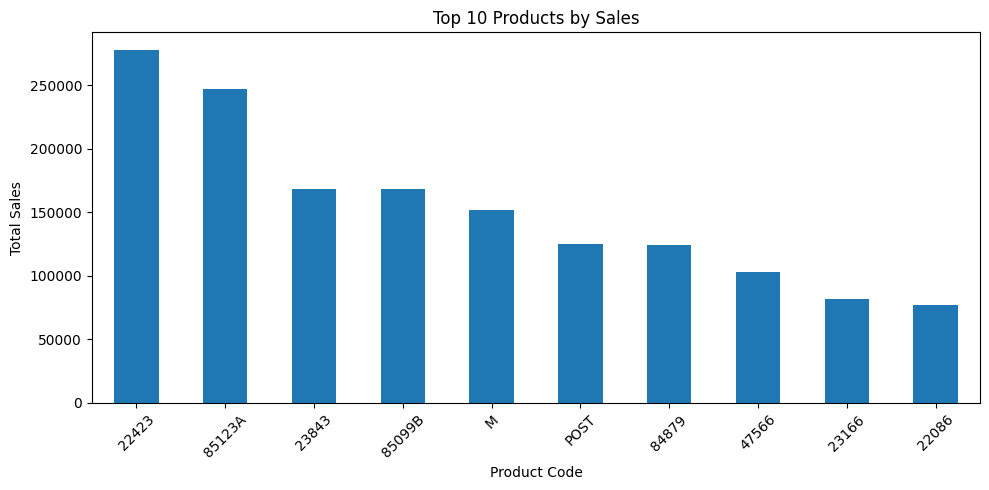

In [ ]:
# Top 10 products by total sales
top_products = (
    df.groupby('StockCode')['TotalSales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

plt.figure(figsize=(10, 5))
top_products.plot(kind='bar')
plt.title('Top 10 Products by Sales')
plt.xlabel('Product Code')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate spending for each customer
customer_sales = df.groupby('Customer ID')['TotalSales'].sum()

print("Total unique customers:", df['Customer ID'].nunique())
print("Average customer spending:", round(customer_sales.mean(), 2))

# Top 10 customers by spending
print("\nTop 10 Customers:")
print(customer_sales.sort_values(ascending=False).head(10))

Total unique customers: 5878
Average customer spending: 2955.9

Top 10 Customers:
Customer ID
18102.0    580987.04
14646.0    528602.52
14156.0    313437.62
14911.0    291420.81
17450.0    244784.25
13694.0    195640.69
17511.0    172132.87
16446.0    168472.50
16684.0    147142.77
12415.0    144458.37
Name: TotalSales, dtype: float64


In [ ]:
import sqlite3
import pandas as pd

# Create a database
conn = sqlite3.connect("ecommerce.db")

# Load cleaned data into SQL table
sql_df = df.copy()
sql_df['Customer ID'] = sql_df['Customer ID'].astype(int)

sql_df.to_sql(
    "retail_sales",
    conn,
    if_exists="replace",
    index=False
)

print("Data loaded into SQL database successfully!")

Data loaded into SQL database successfully!


In [ ]:
query = """
SELECT
    ROUND(SUM(TotalSales), 2) AS total_sales,
    COUNT(DISTINCT Invoice) AS total_orders
FROM retail_sales;
"""

pd.read_sql_query(query, conn)

,total_sales,total_orders
0,17374804.27,36969


In [ ]:
query = """
SELECT
    "Customer ID",
    ROUND(SUM(TotalSales), 2) AS total_spending
FROM retail_sales
GROUP BY "Customer ID"
ORDER BY total_spending DESC
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,Customer ID,total_spending
0,18102,580987.04
1,14646,528602.52
2,14156,313437.62
3,14911,291420.81
4,17450,244784.25
5,13694,195640.69
6,17511,172132.87
7,16446,168472.50
8,16684,147142.77
9,12415,144458.37


In [ ]:
query = """
SELECT
    strftime('%Y-%m', InvoiceDate) AS month,
    ROUND(SUM(TotalSales), 2) AS revenue
FROM retail_sales
GROUP BY month
ORDER BY month;
"""

pd.read_sql_query(query, conn)

,month,revenue
0,2009-12,683504.01
1,2010-01,555802.67
2,2010-02,504558.96
3,2010-03,696978.47
4,2010-04,591982.00
5,2010-05,597833.38
6,2010-06,636371.13
7,2010-07,589736.17
8,2010-08,602224.60
9,2010-09,829013.95


In [ ]:
import pandas as pd
import numpy as np

# Make sure dates are in datetime format
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Use the latest date in the dataset as the reference date
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculate customer-level features
customer_features = df.groupby('Customer ID').agg(
    LastPurchase=('InvoiceDate', 'max'),
    FirstPurchase=('InvoiceDate', 'min'),
    TotalOrders=('Invoice', 'nunique'),
    TotalSpend=('TotalSales', 'sum'),
    TotalQuantity=('Quantity', 'sum')
).reset_index()

# Calculate days since last purchase
customer_features['Recency'] = (
    reference_date - customer_features['LastPurchase']
).dt.days

# Customer tenure in days
customer_features['Tenure'] = (
    customer_features['LastPurchase'] -
    customer_features['FirstPurchase']
).dt.days

# Create a project-defined churn label
customer_features['Churn'] = (
    customer_features['Recency'] > 90
).astype(int)

# Remove dates because we have derived numeric features
customer_features = customer_features.drop(
    columns=['LastPurchase', 'FirstPurchase', 'Customer ID']
)

print("Customer-level dataset created!")
print(customer_features.head())
print("\nChurn distribution:")
print(customer_features['Churn'].value_counts())

Customer-level dataset created!
   TotalOrders  TotalSpend  TotalQuantity  Recency  Tenure  Churn
0           12    77556.46          74285      326     400      1
1            8     4921.53           2967        2     402      0
2            5     2019.40           2714       75     362      0
3            4     4428.69           1624       19     570      0
4            1      334.40            197      310       0      1

Churn distribution:
Churn
1    2989
0    2889
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

X = customer_features.drop(columns=['Churn'])
y = customer_features['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

models = {
    'Logistic Regression': make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced'
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print("\nModel:", name)
    print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
    print(classification_report(y_test, predictions, zero_division=0))


Model: Logistic Regression
Accuracy: 0.9889
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       578
           1       1.00      0.98      0.99       598

    accuracy                           0.99      1176
   macro avg       0.99      0.99      0.99      1176
weighted avg       0.99      0.99      0.99      1176


Model: Random Forest
Accuracy: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       578
           1       1.00      1.00      1.00       598

    accuracy                           1.00      1176
   macro avg       1.00      1.00      1.00      1176
weighted avg       1.00      1.00      1.00      1176



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)

# Recency is excluded because it defines our churn label
X = customer_features.drop(columns=['Churn', 'Recency'])
y = customer_features['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

models = {
    'Logistic Regression': make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight='balanced')
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced'
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, pred), 3),
        'Precision': round(precision_score(y_test, pred, zero_division=0), 3),
        'Recall': round(recall_score(y_test, pred, zero_division=0), 3),
        'F1 Score': round(f1_score(y_test, pred, zero_division=0), 3),
        'ROC-AUC': round(roc_auc_score(y_test, prob), 3)
    })

results_df = pd.DataFrame(results)
print(results_df)

                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression     0.719      0.706   0.769     0.736    0.788
1        Random Forest     0.701      0.703   0.712     0.708    0.777


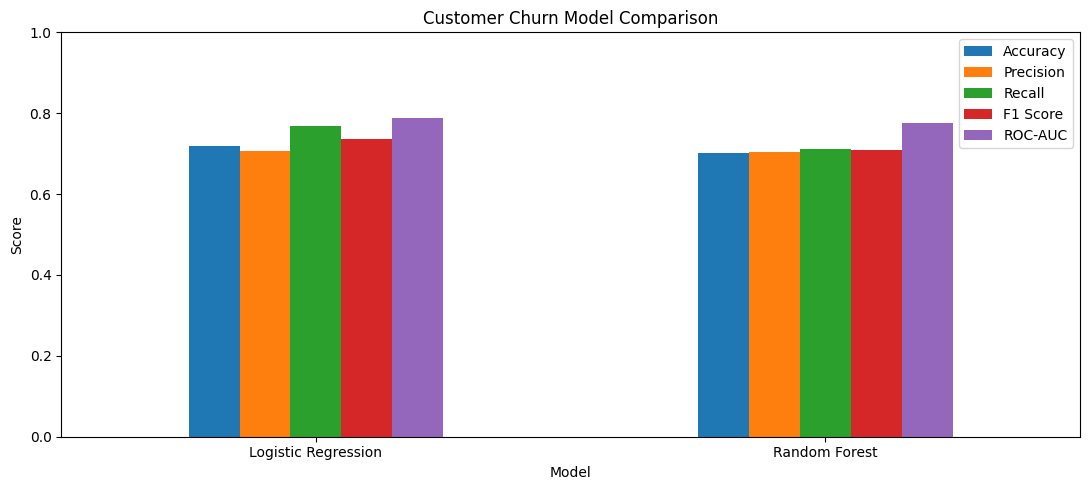

In [ ]:
results_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']].plot(
    kind='bar',
    figsize=(11, 5),
    ylim=(0, 1),
    title='Customer Churn Model Comparison'
)

plt.ylabel('Score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Export cleaned sales data
df.to_csv('/content/cleaned_retail_data.csv', index=False)

# Export customer analytics and churn predictions
best_model_name = results_df.sort_values(
    'F1 Score', ascending=False
).iloc[0]['Model']

best_model = models[best_model_name]

customer_dashboard = customer_features.copy()
customer_dashboard['Predicted_Churn'] = best_model.predict(
    customer_dashboard.drop(columns=['Churn', 'Recency'])
)

customer_dashboard.to_csv(
    '/content/customer_churn_predictions.csv',
    index=False
)

print("Both dashboard files are ready!")

Both dashboard files are ready!
